# Phase 5 — Calibration de JEV

**Question :** quand JEV annonce p(zombie) = 0,8, la cible est-elle un zombie 80 % du temps ?
Et surtout : corriger ses probabilités change-t-il les **décisions** ?

Données : les lectures JEV que la politique demande réellement en jeu (500 parties × 2 langues, réponses réelles de `jev-1.13.0` rejouées depuis le cache). La vérité vient du catalogue du jeu, jamais de JEV.

```bash
node tests/bench.mjs --parties 500 --langue en --lectures bench_resultats/lectures_en.json
node tests/bench.mjs --parties 500 --langue fr --lectures bench_resultats/lectures_fr.json
```

In [1]:
import sys, pathlib
racine = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "analyse" else pathlib.Path.cwd()
sys.path.insert(0, str(racine))
import numpy as np, pandas as pd
from analyse import calibration as cal

tout = cal.charger(sorted((racine / "bench_resultats").glob("lectures_*.json")))
d = tout.filtre(tout.incoh <= cal.INCOH_MAX)
print(f"{len(tout.y)} fiches distinctes, {int(tout.n.sum())} lectures en jeu ; {len(d.y)} fiches cohérentes (utilisées comme preuve)")

50 fiches distinctes, 109717 lectures en jeu ; 24 fiches cohérentes (utilisées comme preuve)


## 1. Piège : 100 000 lectures, mais seulement 24 observations indépendantes

Une même fiche donne toujours la même réponse : répéter une lecture n'apporte aucune information sur une fiche **jamais vue**.
→ les poids (fréquence en jeu) sont normalisés pour sommer au nombre de fiches, et la validation croisée retire **une description entière à la fois** (ses variantes « avant sommation / après réaction / désobéissance » restent ensemble).

In [2]:
res = cal.evaluer(d)
lignes = []
for nom, r in res.items():
    for cas, m in r.items():
        lignes.append({"calibrateur": nom, "évaluation": cas, "Brier": m["brier"], "log-loss": m["log_loss"], "ECE": m["ece"],
                       "marge sécurité": m["marge"], "zombies jamais confirmés": int((m["sommations"] == 99).sum())})
pd.DataFrame(lignes).round(3)

,calibrateur,évaluation,Brier,log-loss,ECE,marge sécurité,zombies jamais confirmés
0,brut (JEV tel quel),dans l'échantillon,0.012,0.086,0.078,0.217,0
1,brut (JEV tel quel),validation croisée,0.012,0.086,0.078,0.217,0
2,"Platt (logistique, 2 paramètres)",dans l'échantillon,0.004,0.036,0.034,0.814,0
3,"Platt (logistique, 2 paramètres)",validation croisée,0.007,0.045,0.040,0.780,0
4,isotonique,dans l'échantillon,0.000,0.010,0.010,6.118,0
5,isotonique,validation croisée,0.002,0.018,0.016,1.601,1


## 2. Diagramme de fiabilité et preuve par fiche

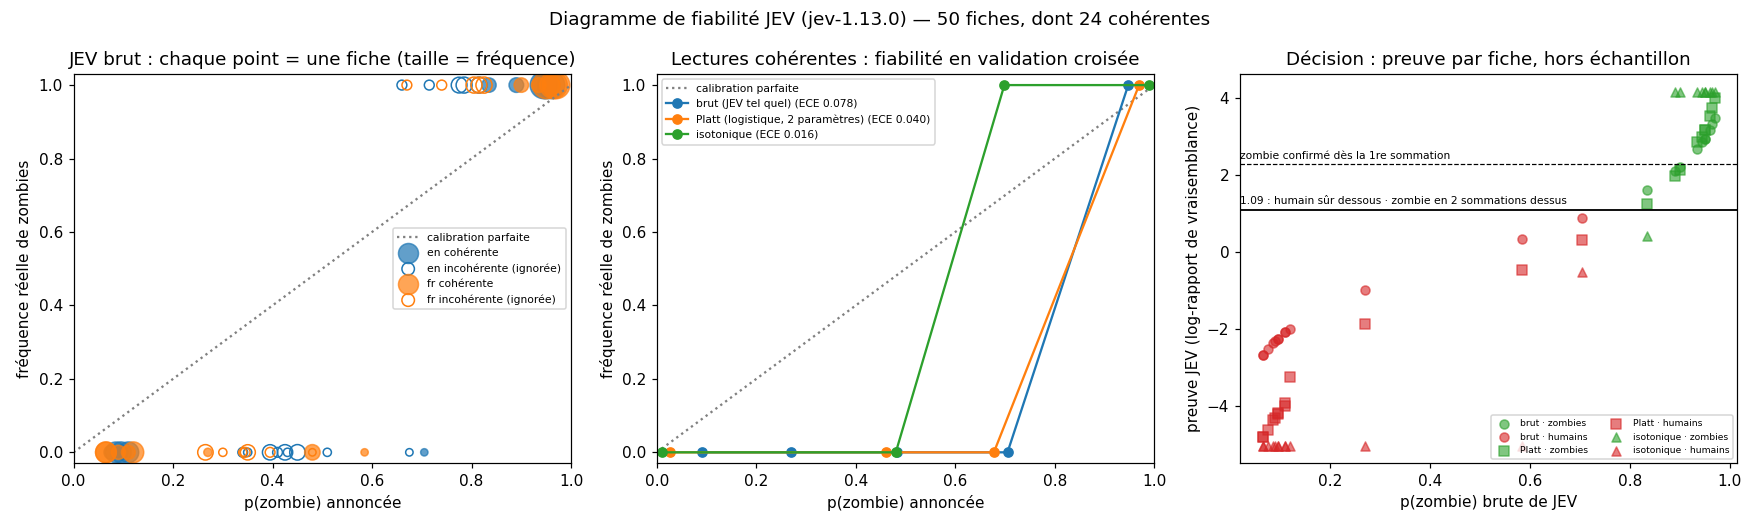

In [3]:
from IPython.display import Image
preds = {C.nom: cal.validation_croisee(d, C) for C in cal.CALIBRATEURS}
cal.figure(tout, d, preds, racine / "analyse" / "fiabilite_jev.png")
Image(filename=str(racine / "analyse" / "fiabilite_jev.png"))

## 3. Lecture

- **JEV brut est sous-confiant** sur les lectures cohérentes (ECE 0,078) : il dit 0,95 pour des fiches qui sont *toujours* des zombies, 0,09 pour des fiches *toujours* humaines.
- **L'isotonique gagne sur toutes les métriques de calibration**, même en validation croisée, mais c'est une fonction en escalier : une fiche inconnue qui tombe dans la marche est mal notée. Hors échantillon, le zombie blessé EN (p = 0,835) n'est **plus jamais confirmé** → 4,2 morsures/partie au benchmark (contre 0,95).
- **Platt (2 paramètres)** : décisions identiques à JEV brut sur 2 × 500 parties (en et hors échantillon, et au stress test à 50 % de désobéissance), mais la marge de sécurité pire cas passe de **0,22 à 0,78** (hors échantillon).

**Leçon :** une meilleure calibration n'est pas une meilleure décision. Le bon critère de choix est mesuré sur la décision, hors échantillon.

**Règle de choix** (`analyse/calibration.choisir`) : meilleure log-loss en validation croisée parmi les calibrateurs qui (1) gardent une marge de sécurité ≥ celle de JEV brut et (2) ne ralentissent la confirmation d'aucune fiche zombie. Le critère (2) a été ajouté **après** avoir vu le benchmark hors échantillon de l'isotonique : à signaler comme tel.

## 4. Dérive

La calibration ne vaut que pour `jev-1.13.0` :
- **passif** (chaque appel) : modèle servi ≠ modèle demandé ⇒ alerte, réponse jamais mise en cache, et la v5 du navigateur repasse en probabilités brutes ;
- **actif** : `python3 -m server.derive` repose 12 questions de référence (1 appel) et compare question par question (|Δp| ≤ 0,10, décalage moyen ≤ 0,05).